In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report

I0000 00:00:1790628327.958849   17857 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790628328.001931   17857 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790628328.985244   17857 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


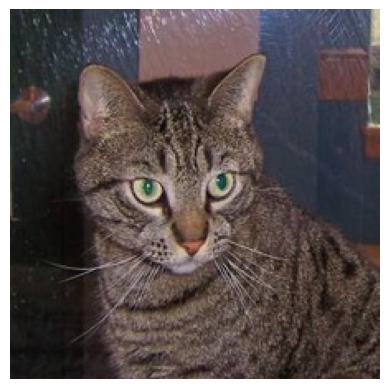

In [2]:
sample_path = Path("Dataset/train/Cat/1.jpg")
img = image.load_img(sample_path)
plt.imshow(img)
plt.axis('off')
plt.show()

In [3]:
img_cv = cv2.imread(str(sample_path))
if img_cv is None:
    raise FileNotFoundError(f"Could not read image: {sample_path.resolve()}")
img_cv.shape

(224, 224, 3)

In [4]:
train = ImageDataGenerator(rescale=1/255)
validation = ImageDataGenerator(rescale=1/255)
test = ImageDataGenerator(rescale=1/255)

In [ ]:
USE_TRANSFER_LEARNING = True      # True = MobileNetV2 (recommended), False = custom CNN
DATA_DIR = 'Dataset'              # change if your folder is elsewhere
CLASS_NAMES = ['Cat', 'Buffalo', 'Elephant', 'Rhino', 'Zebra']
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 30

Found 2999 images belonging to 5 classes.
Found 500 images belonging to 5 classes.
Found 0 images belonging to 5 classes.


In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(256, 3, activation='relu'),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(5, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=50,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(256, 3, activation='relu'),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(5, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=50,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)

test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")

I0000 00:00:1790628330.264563   17857 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2142 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Epoch 1/50


I0000 00:00:1790628330.931755   17857 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1790628331.785459   18008 service.cc:153] XLA service 0x751c500466f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790628331.785477   18008 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1790628331.810597   18008 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1790628332.003494   18008 cuda_dnn.cc:461] Loaded cuDNN version 92600
I0000 00:00:1790628332.044244   18008 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2406__.47


  3/188 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.0833 - loss: 1.6311  

I0000 00:00:1790628340.927240   18008 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 11/188 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.1591 - loss: 1.6223

I0000 00:00:1790628341.635690   18008 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2406__.47


188/188 ━━━━━━━━━━━━━━━━━━━━ 28s 98ms/step - accuracy: 0.3268 - loss: 1.4180 - val_accuracy: 0.4740 - val_loss: 1.2243
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.4555 - loss: 1.2212 - val_accuracy: 0.3860 - val_loss: 1.3214
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.5212 - loss: 1.0625 - val_accuracy: 0.5280 - val_loss: 1.1078
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.5488 - loss: 1.0230 - val_accuracy: 0.5620 - val_loss: 1.0275
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5562 - loss: 0.9938 - val_accuracy: 0.5980 - val_loss: 0.9746
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.5845 - loss: 0.9448 - val_accuracy: 0.5800 - val_loss: 0.9455
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.6059 - loss: 0.9139 - val_accuracy: 0.6220 - val_loss: 0.9029
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.6082 - loss: 0.8720 - val_accuracy: 0.59

NameError: name 'test_acc' is not defined

In [ ]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

In [ ]:
os.makedirs('models', exist_ok=True)
callbacks = [
    tf.keras.callbacks.CSVLogger('history.csv'),
    tf.keras.callbacks.ModelCheckpoint('models/CNN_best_model.keras', save_best_only=True, monitor='val_accuracy')
]

model_fit = model.fit(train_dataset,
                      validation_data=validation_dataset,
                      epochs=50,
                      callbacks=callbacks,
                      shuffle=True)

test_loss, accuracy = model.evaluate(test_dataset)
print(f"Test accuracy: {round(accuracy * 100, 2)}%")

Epoch 1/50


I0000 00:00:1790627375.123783    8538 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1790627376.048643    9781 service.cc:153] XLA service 0x731d2c049c90 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790627376.048670    9781 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1790627376.083665    9781 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1790627376.363291    9781 cuda_dnn.cc:461] Loaded cuDNN version 92600
I0000 00:00:1790627376.411501    9781 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2751__.56


  6/188 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.2083 - loss: 1.6103 

I0000 00:00:1790627385.344031    9781 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


180/188 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1910 - loss: 1.6103

I0000 00:00:1790627389.203210    9788 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2751__.56


188/188 ━━━━━━━━━━━━━━━━━━━━ 26s 83ms/step - accuracy: 0.1904 - loss: 1.6102 - val_accuracy: 0.2000 - val_loss: 1.6095
Epoch 2/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.1961 - loss: 1.6101 - val_accuracy: 0.2000 - val_loss: 1.6095
Epoch 3/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.1884 - loss: 1.6102 - val_accuracy: 0.2000 - val_loss: 1.6094
Epoch 4/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.1707 - loss: 1.6103 - val_accuracy: 0.2000 - val_loss: 1.6094
Epoch 5/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.1894 - loss: 1.6098 - val_accuracy: 0.2000 - val_loss: 1.6094
Epoch 6/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.2057 - loss: 1.6096 - val_accuracy: 0.2000 - val_loss: 1.6094
Epoch 7/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.1907 - loss: 1.6099 - val_accuracy: 0.2000 - val_loss: 1.6094
Epoch 8/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.1881 - loss: 1.6100 - val_accuracy: 0.20

ValueError: The PyDataset has length 0

In [ ]:
his = pd.read_csv('history.csv') 
his.head(10)

,epoch,accuracy,loss,val_accuracy,val_loss
0,0,0.480333,1.301007,0.632,0.867942
1,1,0.711667,0.765616,0.664,0.892397
2,2,0.807667,0.514821,0.758,0.722361
3,3,0.889667,0.313740,0.778,0.688441
4,4,0.944000,0.157260,0.770,0.867333
5,5,0.972333,0.098552,0.780,1.055897
6,6,0.994000,0.020959,0.792,1.345439
7,7,0.993333,0.023818,0.782,1.224300
8,8,0.997333,0.009902,0.818,1.330307
9,9,0.977667,0.074543,0.782,1.454815


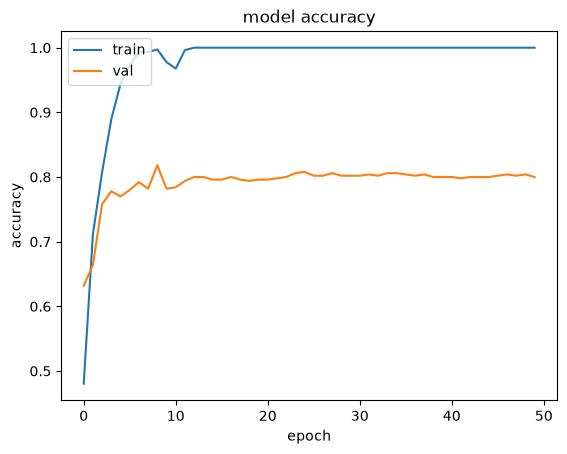

In [ ]:
plt.plot(model_fit.history['accuracy'])
plt.plot(model_fit.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

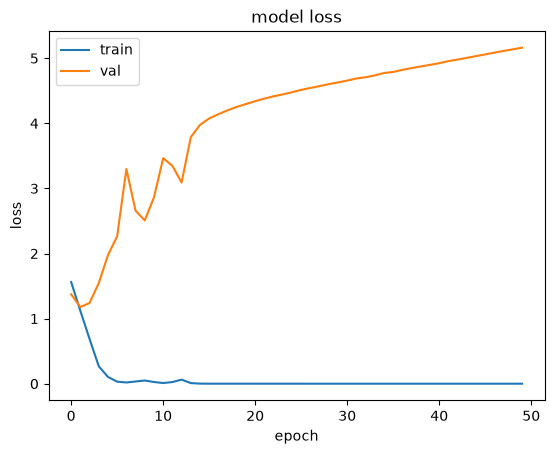

In [ ]:
plt.plot(model_fit.history['loss'])
plt.plot(model_fit.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [ ]:
fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(go.Scatter(y=model_fit.history['val_loss'], name="val_loss"), secondary_y=False)
fig.add_trace(go.Scatter(y=model_fit.history['loss'], name="loss"), secondary_y=False)
fig.add_trace(go.Scatter(y=model_fit.history['val_accuracy'], name="val_accuracy"), secondary_y=True)
fig.add_trace(go.Scatter(y=model_fit.history['accuracy'], name="accuracy"), secondary_y=True)

fig.update_layout(title_text="Loss/Accuracy of Conv2D Model")
fig.update_xaxes(title_text="Number of Epochs")
fig.update_yaxes(title_text="<b>primary</b> Loss", secondary_y=False)
fig.update_yaxes(title_text="<b>secondary</b> Accuracy", secondary_y=True)
fig.show()

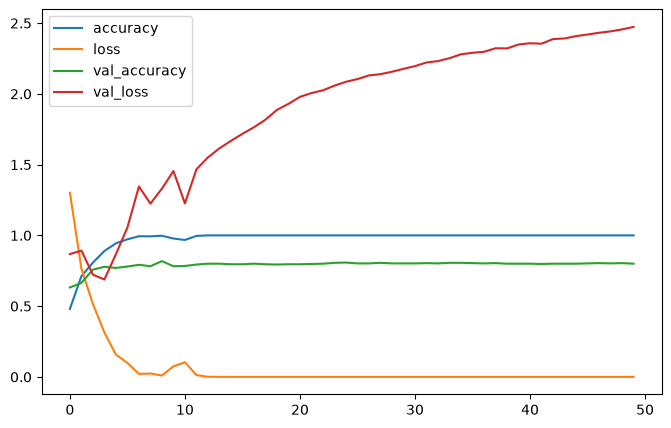

In [ ]:
pd.DataFrame(model_fit.history).plot(figsize=(8,5))
plt.show()

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    22,151,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,533,489 (253.81 MB)

 Trainable params: 22,177,829 (84.60 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 44,355,660 (169.20 MB)

In [ ]:
try:
    from tensorflow.keras.utils import plot_model
    plot_model(model, to_file='convlstm_model_structure_plot.png', show_shapes=True, show_layer_names=True)
except Exception as e:
    print(f"plot_model skipped: {e}")

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


In [ ]:
os.makedirs('models', exist_ok=True)
model.save('models/CNN_predict_model.keras')
model.save('models/CNN_predict_model.h5')
print("Model saved to models/CNN_predict_model.keras and models/CNN_predict_model.h5")

Model saved to models/CNN_predict_model.keras and models/CNN_predict_model.h5


In [ ]:
validation_dataset.class_indices

{'Cat': 0, 'Buffalo': 1, 'Elephant': 2, 'Rhino': 3, 'Zebra': 4}

In [ ]:
labels = list(train_dataset.class_indices.keys())
emoji_map = {'cat': '🐱 Cat', 'cow': '🐮 Cow', 'dog': '🐶 Dog', 'elephant': '🐘 Elephant', 'horse': '🐴 Horse'}

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for idx, class_name in enumerate(labels):
    class_folder = os.path.join('Dataset', 'Test', class_name)
    sample_img_name = os.listdir(class_folder)[0]
    img_path = os.path.join(class_folder, sample_img_name)
    
    img = image.load_img(img_path, target_size=(200, 200, 3))
    axes[idx].imshow(img)
    
    X = image.img_to_array(img) / 255.0
    X = np.expand_dims(X, axis=0)
    pred_prob = model.predict(X, verbose=0)
    pred_class = labels[np.argmax(pred_prob[0])]
    confidence = np.max(pred_prob[0]) * 100
    
    axes[idx].set_title(f"True: {class_name}
Pred: {emoji_map.get(pred_class, pred_class)}
({confidence:.1f}%)"))
    axes[idx].axis('off'))

plt.tight_layout()
    
plt.show()

SyntaxError: unterminated f-string literal (detected at line 19) (2734960191.py, line 19)

In [ ]:
# Predict a sample test image
sample_img = os.path.join('Dataset', 'Test', 'elephant', os.listdir('Dataset/Test/elephant')[0])
img = image.load_img(sample_img, target_size=(200, 200, 3))
plt.imshow(img)
plt.axis('off')
plt.show()

X = image.img_to_array(img) / 255.0
X = np.expand_dims(X, axis=0)
val = model.predict(X, verbose=0)[0]
pred_idx = np.argmax(val)
predicted_label = labels[pred_idx]

print(f"Predicted: {emoji_map.get(predicted_label, predicted_label)} ({val[pred_idx]*100:.2f}% confidence)")

FileNotFoundError: [Errno 2] No such file or directory: 'Dataset/Test/elephant'

In [ ]:
from tensorflow.keras.models import load_model
new_model = load_model('models/CNN_predict_model.keras')

In [ ]:
new_model.summary()